# 🔗 Live Deployment Link: **PASTE_YOUR_STREAMLIT_APP_LINK_HERE**

---
# Laptop Price Prediction System (PKR)
**Course:** Machine Learning Fundamentals (AIC354) | **Assignment 3 – Task 2**

**Problem:** Predict the market price of a laptop (in Pakistani Rupees) from its specifications (brand, CPU, RAM, storage, screen, GPU, OS, weight). This is a **regression** problem, similar to the Car Price Prediction System.

**Approach**
1. Load the **full** laptop dataset and clean it (duplicates, messy text columns) 
2. Convert prices from EUR to PKR
3. Evaluate **5 algorithms not used in the Car Price notebooks** with **10-Fold Cross-Validation**: Ridge Regression, Elastic Net, Extra Trees, Histogram Gradient Boosting, and an MLP Neural Network
4. Compare them with RMSE (primary metric), MAE and R², with tables and charts
5. Save the best model and deploy it as a web app (Streamlit Community Cloud)

> **How to run:** Runtime → *Run all*, then upload `laptop_price.csv` when prompted.

## 1. Import Libraries

In [1]:
import os, re, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from tqdm.auto import tqdm

from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

# --- The 5 algorithms for this assignment ---
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.8.0


### Helper module: a safe price converter
The models predict **log(price)**. A neural network can wildly *extrapolate* on a rare, extreme laptop (e.g. 64 GB RAM) and output an absurd value; after converting back with `exp()` that becomes millions of rupees. We therefore add a fixed **sanity bound** (Rs 20,000 – Rs 2,500,000 for laptops) when converting back. The bounds are domain knowledge, not learned from the data, so there is no data leakage.

The function lives in its own file, `laptop_utils.py`, so the saved model can be loaded by the web app later.

In [2]:
%%writefile laptop_utils.py
# Shared code used by BOTH the notebook and the web app.
import numpy as np
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PRICE_MIN_PKR = 20_000       # cheapest realistic laptop
PRICE_MAX_PKR = 2_500_000    # the most expensive laptop in the dataset is about Rs 1.9 million

TARGET = "Price_PKR"
NUM_FEATURES = ["Inches", "Screen_Width", "Screen_Height", "Cpu_Speed_GHz", "Ram_GB", "SSD_GB", "HDD_GB", "Weight_kg"]
CAT_FEATURES = ["Company", "TypeName", "Touchscreen", "IPS_Panel", "Cpu_Family", "Gpu_Brand", "OpSys"]
FEATURES = ["Company", "TypeName", "Inches", "Screen_Width", "Screen_Height", "Touchscreen", "IPS_Panel",
            "Cpu_Family", "Cpu_Speed_GHz", "Ram_GB", "SSD_GB", "HDD_GB", "Gpu_Brand", "OpSys", "Weight_kg"]


def safe_expm1(log_price):
    # Inverse of log1p, keeping predictions inside a realistic price range
    lo, hi = np.log1p(PRICE_MIN_PKR), np.log1p(PRICE_MAX_PKR)
    return np.expm1(np.clip(log_price, lo, hi))


def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ])


def make_model(estimator):
    # Log-transform the target, fit, then convert predictions back to PKR
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", make_preprocessor()), ("model", estimator)]),
        func=np.log1p, inverse_func=safe_expm1)


def default_best_estimator():
    # Same settings as the best model found by cross-validation in the notebook
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15,
                                         l2_regularization=1.0, random_state=42)


Writing laptop_utils.py


In [3]:
import importlib; importlib.invalidate_caches()
from laptop_utils import (safe_expm1, make_preprocessor, make_model, TARGET,
                          NUM_FEATURES, CAT_FEATURES, FEATURES)

## 2. Load the Dataset
Upload `laptop_price.csv` when prompted (Google Colab). The file uses a Latin-1 encoding, so we read it with `encoding="latin1"`.

In [4]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists("laptop_price.csv"):
    uploaded = files.upload()          # choose laptop_price.csv

raw = pd.read_csv("laptop_price.csv", encoding="latin1")
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (1303, 13)


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


In [5]:
raw.info()
print("\nMissing values:", int(raw.isna().sum().sum()))
print("Duplicate rows (ignoring laptop_ID):", int(raw.drop(columns="laptop_ID").duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   Product           1303 non-null   str    
 3   TypeName          1303 non-null   str    
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   str    
 6   Cpu               1303 non-null   str    
 7   Ram               1303 non-null   str    
 8   Memory            1303 non-null   str    
 9   Gpu               1303 non-null   str    
 10  OpSys             1303 non-null   str    
 11  Weight            1303 non-null   str    
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), str(10)
memory usage: 291.0 KB

Missing values: 0
Duplicate rows (ignoring laptop_ID): 28


## 3. Data Cleaning & Currency Conversion (EUR → PKR)
**Why clean before cross-validation?** The raw file contains 28 duplicate laptops. If duplicates were left in, the same laptop could appear in both a training fold and a validation fold, which makes the scores look better than they really are (*data leakage*). 

Cleaning steps:
- Remove exact duplicates and extra spaces
- `Ram` ("8GB") → number, `Weight` ("1.37kg") → number
- `ScreenResolution` → width, height, touchscreen flag, IPS flag
- `Cpu` → CPU family (Core i5, Ryzen, …) and clock speed in GHz
- `Memory` → total **SSD/Flash** GB and total **HDD/Hybrid** GB (handles "256GB SSD + 1TB HDD")
- `Gpu` → GPU brand; `Mac OS X` merged into `macOS`
- `Product` (600+ unique names) is dropped: it is almost unique per row, so it cannot generalise to new laptops
- Price converted to PKR using the current exchange rate

In [6]:
EUR_TO_PKR = 311.69   # SBP interbank selling rate, 24 Oct 2026 (update if you re-run later)

df = raw.drop_duplicates(subset=[c for c in raw.columns if c != "laptop_ID"]).copy()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip().str.replace(r"\s+", " ", regex=True)

def to_gb(txt):
    m = re.match(r"([\d.]+)(TB|GB)", txt)
    v = float(m.group(1))
    return v * 1024 if m.group(2) == "TB" else v

def storage_split(mem):
    ssd = hdd = 0.0
    for part in mem.split(" + "):
        size = to_gb(part)
        if "SSD" in part or "Flash" in part:
            ssd += size
        else:                      # HDD or Hybrid
            hdd += size
    return pd.Series({"SSD_GB": ssd, "HDD_GB": hdd})

def cpu_family(cpu):
    c = cpu.lower()
    for key, name in [("core i7", "Core i7"), ("core i5", "Core i5"), ("core i3", "Core i3"), ("core m", "Core M"),
                      ("celeron", "Celeron"), ("pentium", "Pentium"), ("atom", "Atom"), ("xeon", "Xeon"),
                      ("ryzen", "Ryzen"), ("fx", "AMD FX"), ("a12", "AMD A-Series"), ("a10", "AMD A-Series"),
                      ("a9", "AMD A-Series"), ("a8", "AMD A-Series"), ("a6", "AMD A-Series"), ("a4", "AMD A-Series"),
                      ("e-series", "AMD E-Series"), ("samsung", "Samsung Exynos")]:
        if key in c:
            return name
    return "Other"

clean = pd.DataFrame({
    "Company":   df["Company"],
    "TypeName":  df["TypeName"],
    "Inches":    df["Inches"],
})
res = df["ScreenResolution"].str.extract(r"(\d{3,4})x(\d{3,4})").astype(int)
clean["Screen_Width"], clean["Screen_Height"] = res[0], res[1]
clean["Touchscreen"] = np.where(df["ScreenResolution"].str.contains("Touchscreen"), "Yes", "No")
clean["IPS_Panel"]   = np.where(df["ScreenResolution"].str.contains("IPS"), "Yes", "No")
clean["Cpu_Family"]  = df["Cpu"].apply(cpu_family)
clean["Cpu_Speed_GHz"] = df["Cpu"].str.extract(r"([\d.]+)GHz")[0].astype(float)
clean["Ram_GB"] = df["Ram"].str.replace("GB", "").astype(int)
clean = clean.join(df["Memory"].apply(storage_split))
clean["Gpu_Brand"] = df["Gpu"].str.split().str[0]
clean["OpSys"]     = df["OpSys"].replace({"Mac OS X": "macOS"})
clean["Weight_kg"] = df["Weight"].str.replace("kg", "").astype(float)
clean["Price_EUR"] = df["Price_euros"]
clean["Price_PKR"] = (df["Price_euros"] * EUR_TO_PKR).round(0)

assert clean.isna().sum().sum() == 0
print(f"Cleaned dataset: {clean.shape[0]} rows x {clean.shape[1]} columns  (removed {len(raw) - len(clean)} duplicates)")
clean.head()

Cleaned dataset: 1275 rows x 17 columns  (removed 28 duplicates)


,Company,TypeName,Inches,Screen_Width,Screen_Height,Touchscreen,IPS_Panel,Cpu_Family,Cpu_Speed_GHz,Ram_GB,SSD_GB,HDD_GB,Gpu_Brand,OpSys,Weight_kg,Price_EUR,Price_PKR
0,Apple,Ultrabook,13.3,2560,1600,No,Yes,Core i5,2.3,8,128.0,0.0,Intel,macOS,1.37,1339.69,417568.0
1,Apple,Ultrabook,13.3,1440,900,No,No,Core i5,1.8,8,128.0,0.0,Intel,macOS,1.34,898.94,280191.0
2,HP,Notebook,15.6,1920,1080,No,No,Core i5,2.5,8,256.0,0.0,Intel,No OS,1.86,575.00,179222.0
3,Apple,Ultrabook,15.4,2880,1800,No,Yes,Core i7,2.7,16,512.0,0.0,AMD,macOS,1.83,2537.45,790898.0
4,Apple,Ultrabook,13.3,2560,1600,No,Yes,Core i5,3.1,8,256.0,0.0,Intel,macOS,1.37,1803.60,562164.0


In [7]:
clean.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Inches,1275.0,15.02,1.43,10.10,14.0,15.60,15.60,18.4
Screen_Width,1275.0,1900.04,493.35,1366.00,1920.0,1920.00,1920.00,3840.0
Screen_Height,1275.0,1073.90,283.88,768.00,1080.0,1080.00,1080.00,2160.0
Cpu_Speed_GHz,1275.0,2.30,0.50,0.90,2.0,2.50,2.70,3.6
Ram_GB,1275.0,8.44,5.10,2.00,4.0,8.00,8.00,64.0
SSD_GB,1275.0,190.77,185.85,0.00,0.0,256.00,256.00,1024.0
HDD_GB,1275.0,429.82,531.07,0.00,0.0,0.00,1024.00,2048.0
Weight_kg,1275.0,2.04,0.67,0.69,1.5,2.04,2.31,4.7
Price_EUR,1275.0,1134.97,700.75,174.00,609.0,989.00,1496.50,6099.0
Price_PKR,1275.0,353758.50,218417.51,54234.00,189819.0,308261.00,466444.50,1900997.0


## 4. Exploratory Data Analysis

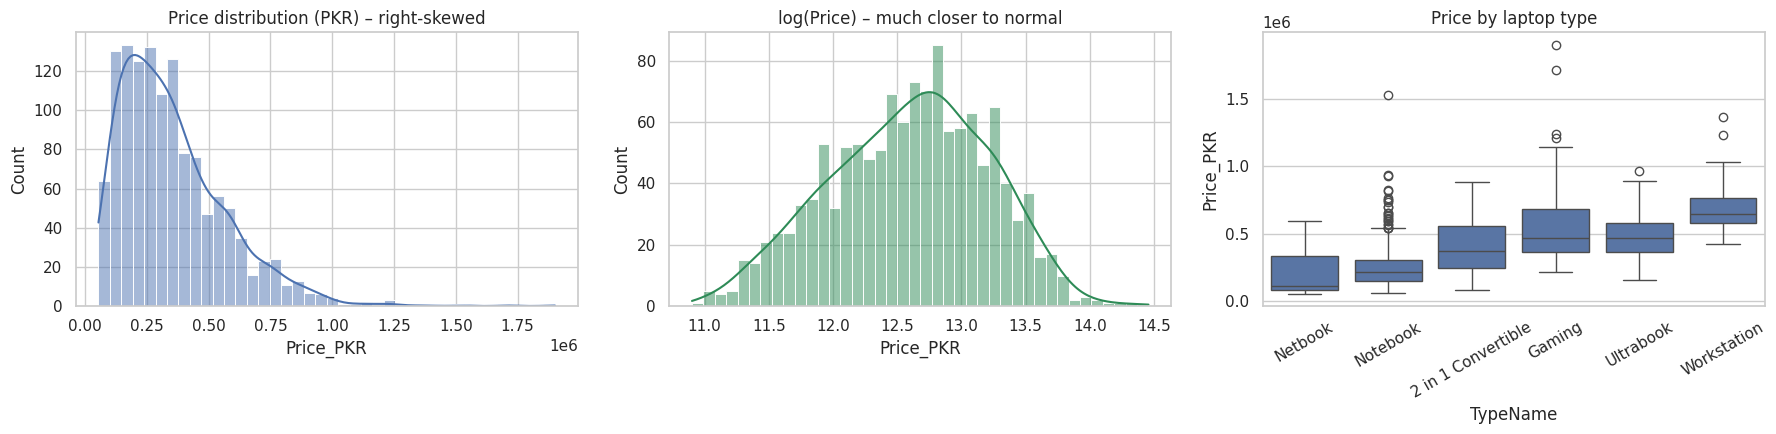

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(clean["Price_PKR"], bins=40, kde=True, ax=ax[0]); ax[0].set_title("Price distribution (PKR) – right-skewed")
sns.histplot(np.log1p(clean["Price_PKR"]), bins=40, kde=True, ax=ax[1], color="seagreen"); ax[1].set_title("log(Price) – much closer to normal")
order = clean.groupby("TypeName")["Price_PKR"].median().sort_values().index
sns.boxplot(data=clean, x="TypeName", y="Price_PKR", order=order, ax=ax[2]); ax[2].tick_params(axis="x", rotation=30)
ax[2].set_title("Price by laptop type")
plt.tight_layout(); plt.show()

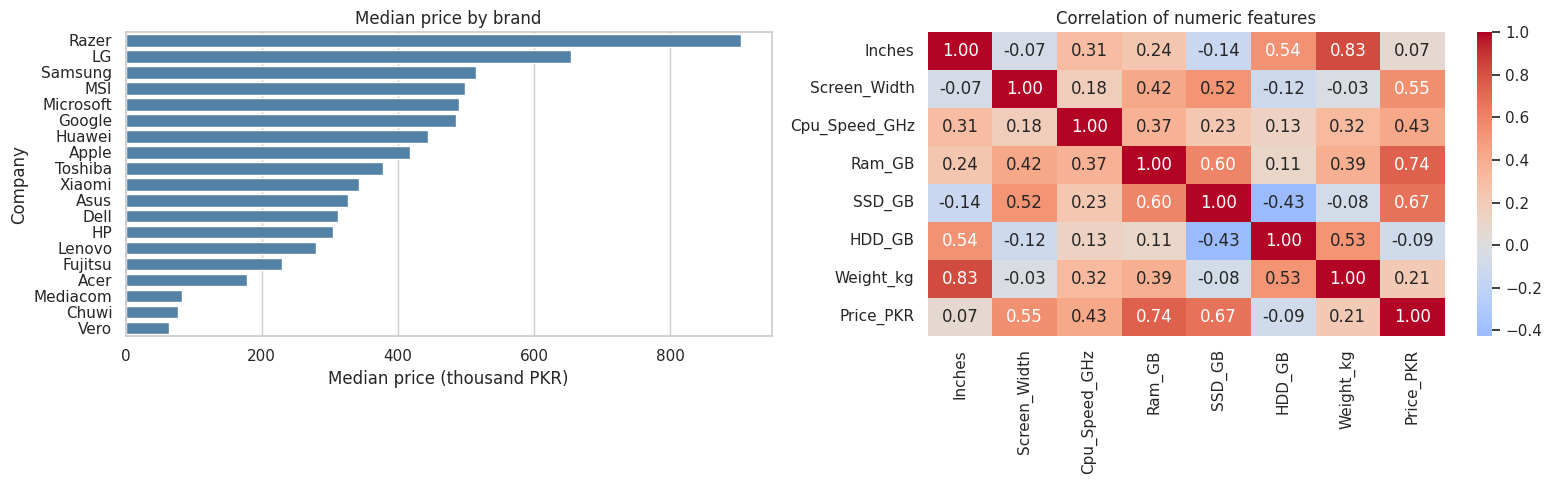

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
top = clean.groupby("Company")["Price_PKR"].median().sort_values(ascending=False)
sns.barplot(x=top.values / 1000, y=top.index, ax=ax[0], color="steelblue")
ax[0].set_xlabel("Median price (thousand PKR)"); ax[0].set_title("Median price by brand")
num_cols = ["Inches", "Screen_Width", "Cpu_Speed_GHz", "Ram_GB", "SSD_GB", "HDD_GB", "Weight_kg", "Price_PKR"]
sns.heatmap(clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Correlation of numeric features")
plt.tight_layout(); plt.show()

**Observations**
- Price is strongly right-skewed. We therefore train on **log(price)** and convert predictions back to PKR; this stops a few very expensive gaming laptops from dominating the error.
- RAM, screen resolution, SSD size and CPU speed show the strongest positive relationship with price; brand and type also matter.

## 5. Features, Target and Pre-processing
- **Numeric features** are standardised (needed by Ridge, Elastic Net and the neural network).
- **Categorical features** are one-hot encoded (`handle_unknown="ignore"` so unseen categories do not crash the app).
- Pre-processing lives **inside the pipeline**, so it is re-fitted on the training part of every fold only (no leakage).

In [10]:
num_features, cat_features = NUM_FEATURES, CAT_FEATURES   # defined in laptop_utils.py

X, y = clean[FEATURES], clean[TARGET]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (1275, 15) | y shape: (1275,)


## 6. The 5 Machine Learning Algorithms
| # | Algorithm | Family | Why it is interesting for this problem |
|---|-----------|--------|----------------------------------------|
| 1 | **Ridge Regression** | Regularised linear | Fast, stable baseline; L2 penalty handles correlated specs (e.g. RAM vs. resolution) |
| 2 | **Elastic Net** | Regularised linear | Mixes L1 + L2, so it can shrink useless one-hot columns to zero |
| 3 | **Extra Trees** | Randomised tree ensemble (bagging) | Captures non-linear spec interactions; very low variance |
| 4 | **Histogram Gradient Boosting** | Boosted trees | Strong on tabular data; learns from the previous trees' mistakes |
| 5 | **MLP Neural Network** | Neural network | Learns smooth non-linear patterns; sensitive to scaling (handled in the pipeline) |

In [11]:
models = {
    "Ridge Regression":      Ridge(alpha=1.0),
    "Elastic Net":           ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000, random_state=RANDOM_STATE),
    "Extra Trees":           ExtraTreesRegressor(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15,
                                                           l2_regularization=1.0, random_state=RANDOM_STATE),
    "MLP Neural Network":    MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, early_stopping=True,
                                          max_iter=2000, random_state=RANDOM_STATE),
}
print("Models to evaluate:", list(models))

Models to evaluate: ['Ridge Regression', 'Elastic Net', 'Extra Trees', 'Hist Gradient Boosting', 'MLP Neural Network']


## 7. 10-Fold Cross-Validation on the Full Dataset
Every laptop is used for validation exactly once. For each fold we record **RMSE** (primary metric, in PKR), **MAE**, **R²** and training time. The progress bar shows the time remaining.

In [12]:
N_SPLITS = 10
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
folds = list(kf.split(X))

records, oof_pred = [], {name: np.zeros(len(y)) for name in models}
total_steps = len(models) * N_SPLITS
t0 = time.time()

with tqdm(total=total_steps, desc="10-fold CV", unit="fit") as bar:
    for name, est in models.items():
        for k, (tr, va) in enumerate(folds, start=1):
            bar.set_postfix(model=name, fold=f"{k}/{N_SPLITS}")
            m = make_model(est)
            t = time.time()
            m.fit(X.iloc[tr], y.iloc[tr])
            fit_time = time.time() - t
            pred = m.predict(X.iloc[va])
            oof_pred[name][va] = pred
            records.append({
                "Model": name, "Fold": k,
                "RMSE": np.sqrt(mean_squared_error(y.iloc[va], pred)),
                "MAE":  mean_absolute_error(y.iloc[va], pred),
                "R2":   r2_score(y.iloc[va], pred),
                "MAPE": mean_absolute_percentage_error(y.iloc[va], pred),
                "Fit_time_s": fit_time,
            })
            bar.update(1)

fold_results = pd.DataFrame(records)
print(f"\nFinished in {time.time() - t0:.1f} seconds")


Finished in 55.8 seconds


## 8. Results & Comparison

In [13]:
summary = (fold_results.groupby("Model")
           .agg(RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
                MAE_mean=("MAE", "mean"), R2_mean=("R2", "mean"),
                MAPE_mean=("MAPE", "mean"), Fit_time_s=("Fit_time_s", "mean"))
           .sort_values("RMSE_mean").reset_index())
summary.insert(0, "Rank", range(1, len(summary) + 1))
display(summary.style.format({"RMSE_mean": "{:,.0f}", "RMSE_std": "{:,.0f}", "MAE_mean": "{:,.0f}",
                              "R2_mean": "{:.3f}", "MAPE_mean": "{:.1%}", "Fit_time_s": "{:.2f}"})
        .background_gradient(subset=["RMSE_mean"], cmap="RdYlGn_r").hide(axis="index"))
best_name = summary.loc[0, "Model"]
print(f"\n🏆 Best model by 10-fold CV RMSE: {best_name}  (RMSE = Rs {summary.loc[0, 'RMSE_mean']:,.0f})")

Rank,Model,RMSE_mean,RMSE_std,MAE_mean,R2_mean,MAPE_mean,Fit_time_s
1,Hist Gradient Boosting,"88,880","13,380","54,145",0.831,14.8%,0.85
2,Extra Trees,"97,527","19,708","60,365",0.793,16.7%,2.22
3,Ridge Regression,"109,810","17,924","69,958",0.734,19.0%,0.02
4,Elastic Net,"111,083","18,154","70,776",0.728,19.1%,0.02
5,MLP Neural Network,"116,500","26,827","72,519",0.692,19.9%,2.32



🏆 Best model by 10-fold CV RMSE: Hist Gradient Boosting  (RMSE = Rs 88,880)


In [14]:
per_fold = fold_results.pivot(index="Fold", columns="Model", values="RMSE")[summary["Model"]]
display(per_fold.style.format("{:,.0f}").set_caption("RMSE (PKR) for each of the 10 folds"))

Model,Hist Gradient Boosting,Extra Trees,Ridge Regression,Elastic Net,MLP Neural Network
Fold,,,,,
1,"92,549","71,818","89,134","90,613","116,321"
2,"95,056","104,987","105,823","106,187","133,277"
3,"102,757","134,014","99,605","102,758","92,653"
4,"76,963","83,722","125,072","126,204","94,399"
5,"83,255","91,092","104,943","108,192","119,122"
6,"89,710","104,309","144,651","144,994","159,360"
7,"93,295","89,287","105,433","104,853","95,686"
8,"83,299","102,396","104,817","105,597","101,404"
9,"109,675","120,032","129,670","133,054","161,303"


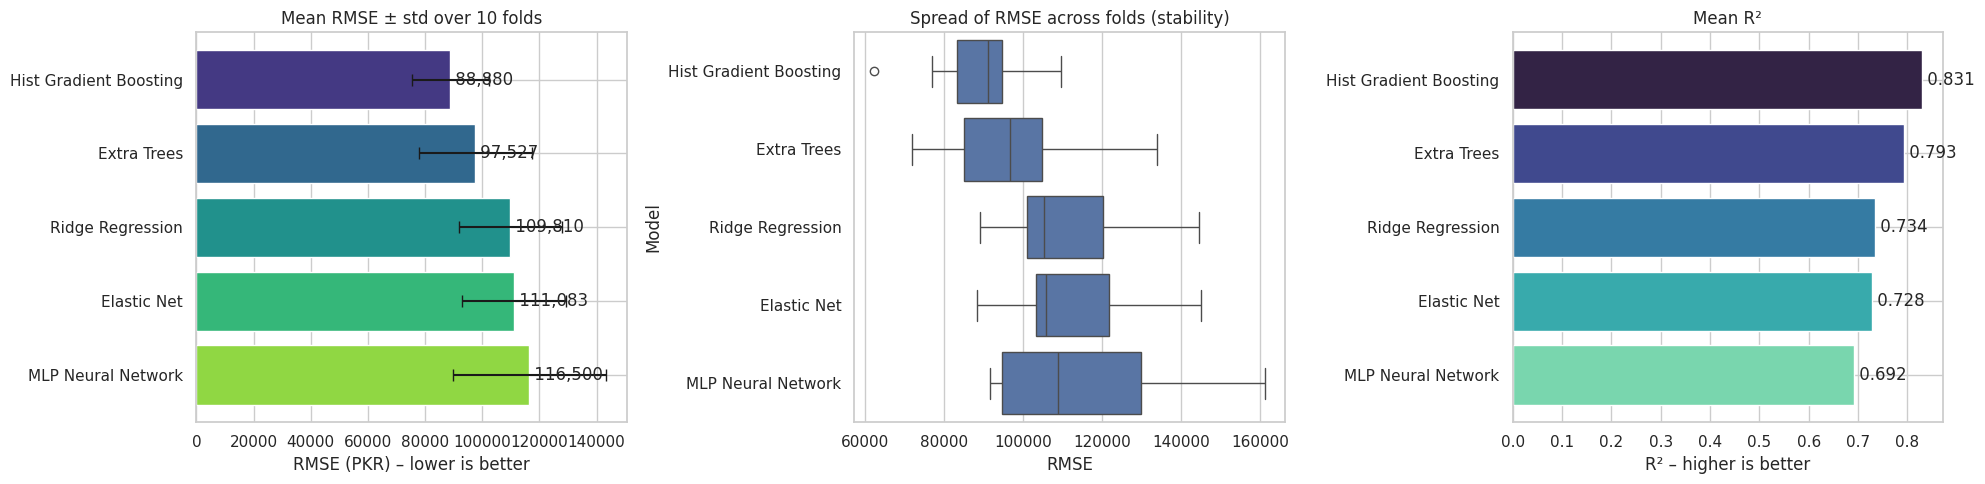

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
order = summary["Model"].tolist()

ax[0].barh(order, summary["RMSE_mean"], xerr=summary["RMSE_std"], color=sns.color_palette("viridis", len(order)), capsize=4)
ax[0].invert_yaxis(); ax[0].set_xlabel("RMSE (PKR) – lower is better"); ax[0].set_title("Mean RMSE ± std over 10 folds")
for i, v in enumerate(summary["RMSE_mean"]): ax[0].text(v, i, f" {v:,.0f}", va="center")

sns.boxplot(data=fold_results, x="RMSE", y="Model", order=order, ax=ax[1])
ax[1].set_title("Spread of RMSE across folds (stability)")

ax[2].barh(order, summary["R2_mean"], color=sns.color_palette("mako", len(order)))
ax[2].invert_yaxis(); ax[2].set_xlabel("R² – higher is better"); ax[2].set_title("Mean R²")
for i, v in enumerate(summary["R2_mean"]): ax[2].text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

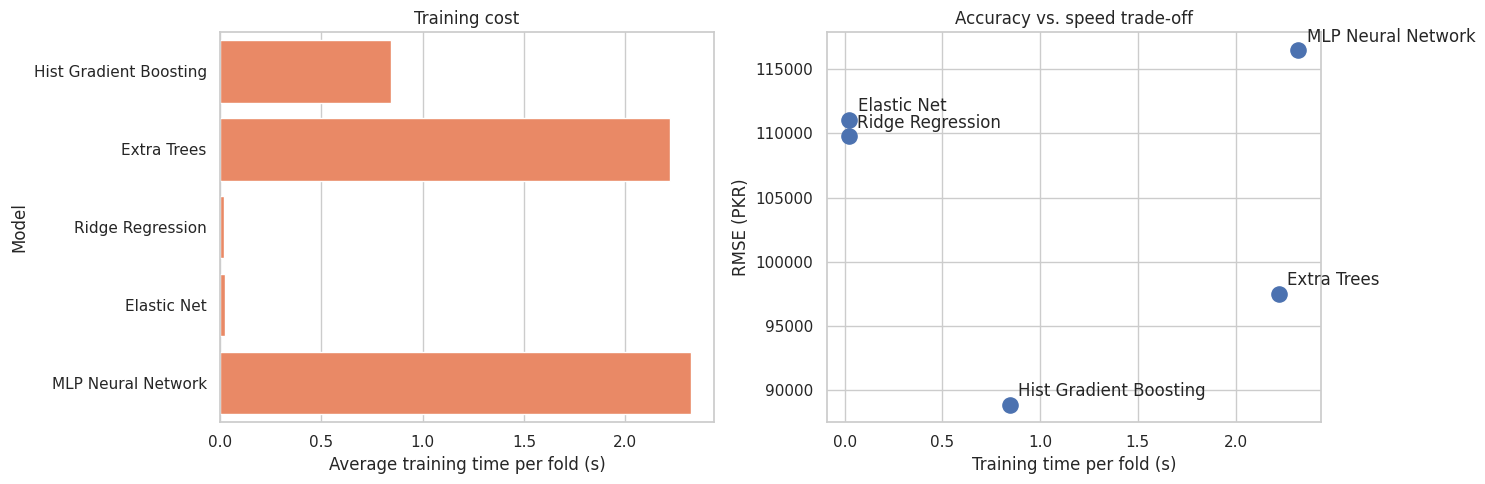

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=summary, y="Model", x="Fit_time_s", ax=ax[0], color="coral")
ax[0].set_xlabel("Average training time per fold (s)"); ax[0].set_title("Training cost")
ax[1].scatter(summary["Fit_time_s"], summary["RMSE_mean"], s=120)
for _, r in summary.iterrows(): ax[1].annotate(r["Model"], (r["Fit_time_s"], r["RMSE_mean"]), xytext=(6, 6), textcoords="offset points")
ax[1].set_xlabel("Training time per fold (s)"); ax[1].set_ylabel("RMSE (PKR)"); ax[1].set_title("Accuracy vs. speed trade-off")
plt.tight_layout(); plt.show()

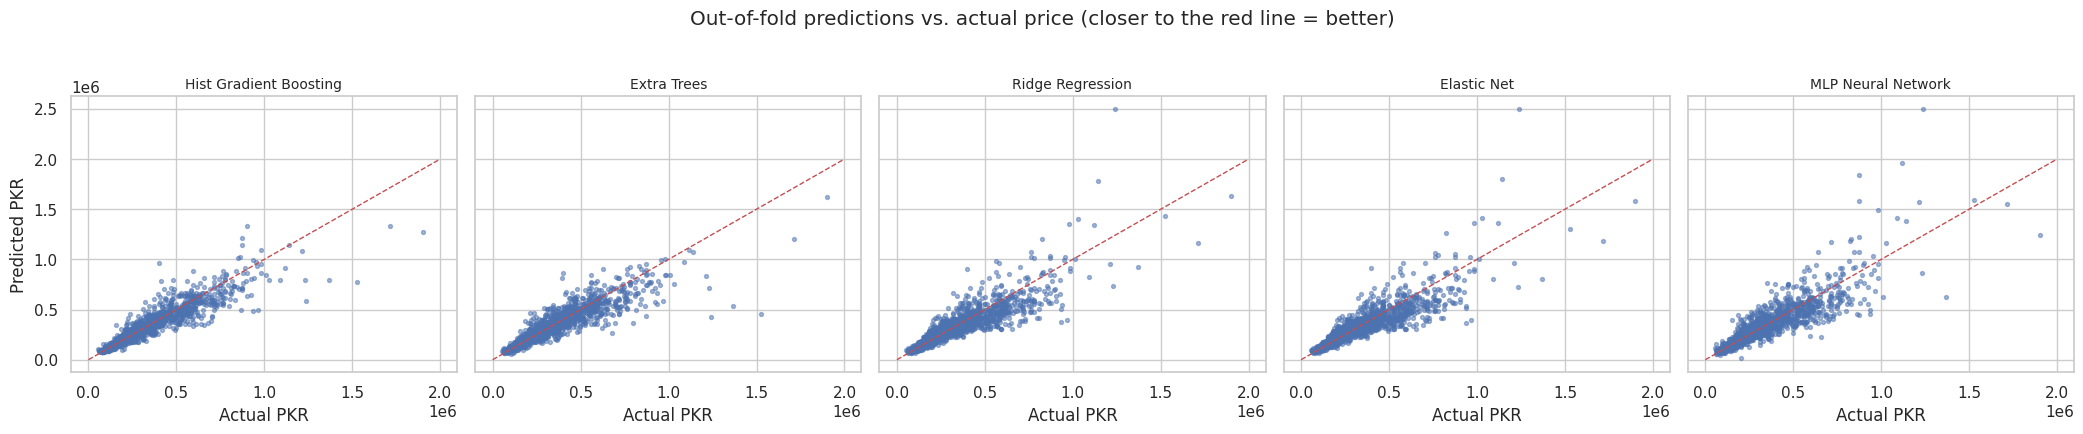

In [17]:
# Predicted vs. actual for every model, using out-of-fold predictions (each laptop predicted by a model that never saw it)
fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 4.2), sharex=True, sharey=True)
lim = [0, y.max() * 1.05]
for ax_, name in zip(axes, order):
    ax_.scatter(y, oof_pred[name], s=8, alpha=0.5)
    ax_.plot(lim, lim, "r--", lw=1); ax_.set_title(name, fontsize=10); ax_.set_xlabel("Actual PKR")
axes[0].set_ylabel("Predicted PKR")
plt.suptitle("Out-of-fold predictions vs. actual price (closer to the red line = better)", y=1.03)
plt.tight_layout(); plt.show()

## 9. Discussion
Read the table and charts above to answer these questions for your report:
- **Which model has the lowest RMSE and highest R²?** (ranked table)
- **Is the winner also stable?** Look at the box-plot: a small spread means it performs consistently on every fold.
- **Linear vs. non-linear:** compare Ridge/Elastic Net with the tree and neural models. A big gap means price depends on non-linear interactions between specs (for example, RAM matters more on a gaming laptop than on a netbook).
- **Cost vs. accuracy:** the scatter plot shows whether the extra training time of a model is worth the accuracy gain.

## 10. Train the Final Model & Save It
The best model from cross-validation is re-trained on **all** the data, then saved together with a small metadata file (`model_meta.json`) that the web app uses to build its input form.

In [18]:
final_model = make_model(models[best_name])
final_model.fit(X, y)

MODEL_FILE, META_FILE = "laptop_price_model.joblib", "model_meta.json"
joblib.dump(final_model, MODEL_FILE, compress=3)

best_row = summary.iloc[0]
resolutions = (clean.assign(r=clean["Screen_Width"].astype(str) + "x" + clean["Screen_Height"].astype(str))["r"]
               .value_counts().index.tolist())
meta = {
    "best_model": best_name,
    "cv_rmse_pkr": float(best_row["RMSE_mean"]),
    "cv_r2": float(best_row["R2_mean"]),
    "cv_mape": float(best_row["MAPE_mean"]),
    "eur_to_pkr": EUR_TO_PKR,
    "sklearn_version": sklearn.__version__,
    "features": FEATURES,
    "categories": {c: sorted(clean[c].unique().tolist()) for c in cat_features if c not in ("Touchscreen", "IPS_Panel")},
    "numeric": {c: {"min": float(clean[c].min()), "max": float(clean[c].max()), "default": float(round(clean[c].median(), 2))}
                for c in ["Inches", "Cpu_Speed_GHz", "Weight_kg"]},
    "resolutions": resolutions, "default_resolution": "1920x1080",
    "ram_options": sorted(clean["Ram_GB"].unique().tolist()),
    "ssd_options": sorted(clean["SSD_GB"].astype(int).unique().tolist()),
    "hdd_options": sorted(clean["HDD_GB"].astype(int).unique().tolist()),
}
with open(META_FILE, "w") as f:
    json.dump(meta, f, indent=2)
clean.to_csv("laptop_clean.csv", index=False)
print(f"Saved {MODEL_FILE} ({os.path.getsize(MODEL_FILE)/1024:.0f} KB) and {META_FILE}")

Saved laptop_price_model.joblib (241 KB) and model_meta.json


In [19]:
# Sanity check: reload the saved model and predict a new laptop
loaded = joblib.load(MODEL_FILE)
sample = pd.DataFrame([{
    "Company": "Dell", "TypeName": "Notebook", "Inches": 15.6, "Screen_Width": 1920, "Screen_Height": 1080,
    "Touchscreen": "No", "IPS_Panel": "Yes", "Cpu_Family": "Core i5", "Cpu_Speed_GHz": 2.5, "Ram_GB": 8,
    "SSD_GB": 256, "HDD_GB": 0, "Gpu_Brand": "Intel", "OpSys": "Windows 10", "Weight_kg": 2.0}])[FEATURES]
print(f"Predicted price: Rs {loaded.predict(sample)[0]:,.0f}")

Predicted price: Rs 355,487


## 11. Model Deployment (Streamlit Community Cloud → Web App)
The next cells write the files the cloud needs: **`app.py`** (web interface), **`requirements.txt`** (flexible versions; if the saved model cannot be loaded on the server, the app automatically retrains it from `laptop_clean.csv`) and a zip of everything.

**Steps to go live (free):**
1. Run the next two cells and download `deploy_package.zip`.
2. Create a new **public GitHub repository** and upload the files inside the zip: `app.py`, `laptop_utils.py`, `requirements.txt`, `laptop_price_model.joblib`, `model_meta.json`, `laptop_clean.csv`, `README.md`.
3. Go to **share.streamlit.io** → sign in with GitHub → **Create app** → choose your repo, branch `main`, main file `app.py` → **Deploy**.
4. After a minute you get a link like `https://your-app-name.streamlit.app`. 
5. **Paste this link in the first cell at the top of this notebook** (as required by the assignment) and submit the notebook, dataset and `laptop_price_model.joblib` to Google Classroom.

In [20]:
%%writefile app.py
import json
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

import laptop_utils as lu

BASE = Path(__file__).parent
MODEL_PATH = BASE / "laptop_price_model.joblib"
META_PATH = BASE / "model_meta.json"
DATA_PATH = BASE / "laptop_clean.csv"

st.set_page_config(page_title="Laptop Price Predictor (PKR)", page_icon="💻", layout="centered")


@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)


@st.cache_resource(show_spinner="Loading model...")
def load_model():
    """Load the saved model; if it cannot be loaded or used (e.g. a different
    scikit-learn version on the server), retrain the same model on startup."""
    data = load_data()
    try:
        model = joblib.load(MODEL_PATH)
        model.predict(data[lu.FEATURES].head(2))          # smoke test
        return model, "saved model"
    except Exception:
        model = lu.make_model(lu.default_best_estimator())
        model.fit(data[lu.FEATURES], data[lu.TARGET])
        return model, "retrained on start-up (server library versions differ from training)"


def first_index(options, value, fallback=0):
    return options.index(value) if value in options else fallback


meta = json.loads(META_PATH.read_text())
data = load_data()
model, model_source = load_model()
cats, nums = meta["categories"], meta["numeric"]

st.title("💻 Laptop Price Predictor")
st.caption("Estimate the market price of a laptop in Pakistani Rupees (PKR) from its specifications.")

m1, m2, m3 = st.columns(3)
m1.metric("Model", meta["best_model"])
m2.metric("10-fold CV RMSE", f"Rs {meta['cv_rmse_pkr']:,.0f}")
m3.metric("10-fold CV R²", f"{meta['cv_r2']:.2f}")

st.subheader("Laptop specifications")
c1, c2 = st.columns(2)
with c1:
    company = st.selectbox("Brand", cats["Company"], index=first_index(cats["Company"], "Dell"))
    type_name = st.selectbox("Type", cats["TypeName"], index=first_index(cats["TypeName"], "Notebook"))
    cpu_family = st.selectbox("Processor family", cats["Cpu_Family"], index=first_index(cats["Cpu_Family"], "Core i5"))
    gpu_brand = st.selectbox("Graphics card brand", cats["Gpu_Brand"], index=first_index(cats["Gpu_Brand"], "Intel"))
    opsys = st.selectbox("Operating system", cats["OpSys"], index=first_index(cats["OpSys"], "Windows 10"))
    touch = st.radio("Touchscreen", ["No", "Yes"], horizontal=True)
    ips = st.radio("IPS panel", ["No", "Yes"], horizontal=True)
with c2:
    inches = st.number_input("Screen size (inches)", nums["Inches"]["min"], nums["Inches"]["max"], nums["Inches"]["default"], 0.1)
    res = st.selectbox("Screen resolution", meta["resolutions"], index=first_index(meta["resolutions"], meta["default_resolution"]))
    cpu_ghz = st.number_input("CPU speed (GHz)", nums["Cpu_Speed_GHz"]["min"], nums["Cpu_Speed_GHz"]["max"], nums["Cpu_Speed_GHz"]["default"], 0.1)
    ram = st.selectbox("RAM (GB)", meta["ram_options"], index=first_index(meta["ram_options"], 8))
    ssd = st.selectbox("SSD / Flash storage (GB)", meta["ssd_options"], index=first_index(meta["ssd_options"], 256))
    hdd = st.selectbox("HDD / Hybrid storage (GB)", meta["hdd_options"], index=0)
    weight = st.number_input("Weight (kg)", nums["Weight_kg"]["min"], nums["Weight_kg"]["max"], nums["Weight_kg"]["default"], 0.05)

if st.button("Predict price", type="primary"):
    if ssd == 0 and hdd == 0:
        st.warning("Please choose at least one storage drive (SSD or HDD).")
        st.stop()
    w, h = (int(v) for v in res.split("x"))
    row = pd.DataFrame([{
        "Company": company, "TypeName": type_name, "Inches": inches,
        "Screen_Width": w, "Screen_Height": h, "Touchscreen": touch, "IPS_Panel": ips,
        "Cpu_Family": cpu_family, "Cpu_Speed_GHz": cpu_ghz, "Ram_GB": ram,
        "SSD_GB": ssd, "HDD_GB": hdd, "Gpu_Brand": gpu_brand, "OpSys": opsys, "Weight_kg": weight,
    }])[lu.FEATURES]

    try:
        pkr = float(model.predict(row)[0])
    except Exception as exc:
        st.error(f"Prediction failed: {exc}")
        st.stop()

    low, high = pkr * (1 - meta["cv_mape"]), pkr * (1 + meta["cv_mape"])
    st.success(f"Estimated price: **Rs {pkr:,.0f}**")
    st.write(f"Likely range (± the model's average error of {meta['cv_mape'] * 100:.0f}%): "
             f"**Rs {low:,.0f} – Rs {high:,.0f}**  (≈ €{pkr / meta['eur_to_pkr']:,.0f} at 1 EUR = {meta['eur_to_pkr']} PKR)")

    # Similar laptops from the training data, as a reality check
    d = data.copy()
    dist = (
        (d["Ram_GB"] - ram).abs() / 8 + (d["SSD_GB"] - ssd).abs() / 256 + (d["Inches"] - inches).abs() / 2
        + (d["TypeName"] != type_name) * 1.0 + (d["Cpu_Family"] != cpu_family) * 1.0 + (d["Company"] != company) * 0.5
    )
    similar = d.loc[dist.nsmallest(5).index, ["Company", "TypeName", "Cpu_Family", "Ram_GB", "SSD_GB", "HDD_GB", "Inches", "Price_PKR"]]
    similar = similar.rename(columns={"Cpu_Family": "CPU", "Ram_GB": "RAM (GB)", "SSD_GB": "SSD (GB)", "HDD_GB": "HDD (GB)", "Price_PKR": "Price (PKR)"})
    st.markdown("**Most similar laptops in the dataset**")
    st.dataframe(similar.style.format({"Price (PKR)": "Rs {:,.0f}", "SSD (GB)": "{:.0f}", "HDD (GB)": "{:.0f}"}),
                 hide_index=True)

st.divider()
st.caption(
    f"Trained on {len(data):,} unique laptops (Kaggle laptop price dataset, 2017-2018 market, EUR converted to PKR). "
    f"Estimates are indicative only. Model source: {model_source}."
)

Writing app.py


In [21]:
import importlib.metadata as md_, zipfile
with open("requirements.txt", "w") as f:
    f.write("# Flexible versions: the app retrains automatically if the saved model cannot be loaded\n")
    f.write("streamlit>=1.30\npandas>=2.0\nnumpy>=1.24\njoblib>=1.3\nscikit-learn>=1.3\n")
    f.write(f"# model trained with scikit-learn {md_.version('scikit-learn')}\n")

with open("README.md", "w") as f:
    f.write("# Laptop Price Predictor (PKR)\n\nStreamlit web app. Run locally: `pip install -r requirements.txt` then `streamlit run app.py`.\n"
            "Deploy: upload these files to a public GitHub repo, then create an app at share.streamlit.io with main file `app.py`.\n")

DEPLOY_FILES = ["app.py", "laptop_utils.py", "requirements.txt", MODEL_FILE, META_FILE, "laptop_clean.csv", "README.md"]
for fn in DEPLOY_FILES:
    assert os.path.exists(fn), fn
with zipfile.ZipFile("deploy_package.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in DEPLOY_FILES:
        z.write(fn)
print("Created deploy_package.zip with:", DEPLOY_FILES)
if IN_COLAB:
    files.download("deploy_package.zip")
    files.download(MODEL_FILE)

Created deploy_package.zip with: ['app.py', 'laptop_utils.py', 'requirements.txt', 'laptop_price_model.joblib', 'model_meta.json', 'laptop_clean.csv', 'README.md']


## 12. Conclusion
Fill in your own numbers from Section 8 here:
- **Best model:** *(name)* with a 10-fold CV RMSE of about Rs *(value)* and R² of *(value)*.
- Tree ensembles / boosting usually beat the linear models here because laptop prices depend on non-linear interactions between specs.
- **Limitations:** the dataset is from a European market snapshot (2017–2018) converted to PKR at one fixed exchange rate; it does not include current CPUs/GPUs or local market premiums. Predictions are indicative, not exact.
- **Future work:** add newer data, tune hyper-parameters with nested cross-validation, try CatBoost/XGBoost, and refresh the exchange rate automatically.